# SAM3 (facebook/sam3) 품질검수 로컬 테스트 — 하자 탐지 백엔드 후보 검증

**스파이크/검증용 코드입니다. 프로덕션 코드가 아닙니다.**

상품 이미지에서 하자(오염·스크래치·찢김·구멍)를 **텍스트 프롬프트로** 탐지하는 QC 서비스의
MVP 프로토타입 검증. 현재 프로덕션 백엔드는 CLIPSeg(`CIDAS/clipseg-rd64-refined`)인데,
LAB-12 실측에서 **오염은 양호하지만 찢어짐·훼손은 약하다**는 한계가 확인됐다.
SAM3 의 PCS(Promptable Concept Segmentation)는 명사구 하나로 **모든 인스턴스를 개별
마스크 + 박스 + score 로** 뽑아 주므로, "하자 개수 세기"와 "부위 넘버링"에 구조적으로 더 맞다.

- 모델: [`facebook/sam3`](https://huggingface.co/facebook/sam3) — **gated repo**(약관 동의 필요)
- 실행 환경: 로컬 노트북, **RTX 4070 Laptop / VRAM 8GB** — 이 안에서 구동돼야 한다
- 범위: 로컬 테스트·검증만. 큐잉·비동기 처리 등 운영 로직은 범위 밖

> **이 노트북은 마스킹(배경 검정) 버전이다.** 의류 bbox 로 자른 뒤 마스크 밖(의류가
> 아닌 픽셀)을 검정(0)으로 채우고 그 안에서 탐지한다. 크롭 사각형 안 배경을 그대로
> 두는 버전은 자매 노트북 `sam3_qc_test_bbox_crop.ipynb` — 크롭 좌표·크기·나머지 파이프
> 라인은 완전히 동일하고 이 배경 처리 한 가지만 다르다.

### 이 노트북이 답하려는 질문

1. 영어 명사구 프롬프트로 하자가 실제로 잡히는가 (§1, §3)
2. **한국어 프롬프트가 실사용에 먹히는가** (§2) — SAM3 텍스트 인코더는 CLIP 계열이라 회의적
3. 8GB VRAM 안에서 반복 추론이 안정적인가, 메모리가 누적되지 않는가 (§4)
4. 판정(PASS/REVIEW/FAIL)과 근거 자료(넘버링 bbox, semantic_seg 히트맵)를 뽑을 수 있는가 (§5~§7)
5. **마스크 경계가 정제(refinement)를 필요로 할 만큼 거친가** (§8) → 필요하면 §9

### 실행 순서

셀을 위에서 아래로 순서대로 실행한다. §9는 기본으로 꺼져 있고(`RUN_TRACKER_REFINE = False`),
§8을 눈으로 확인한 뒤 필요하다고 판단될 때만 켠다.

> VRAM 최소화를 위해 §8까지는 **`Sam3Model` / `Sam3Processor` 만** 임포트한다.
> `Sam3VideoModel` · `Sam3TrackerModel` 등 video/tracker 계열은 §9에서만 등장한다.

## 0. 의존성 설치

`requirements-sam3.txt` 를 설치한다. **`validation/requirements-test.txt` 와 같은 환경에
설치하면 안 된다** — 그쪽은 Kanana 때문에 `transformers<5` 로 핀이 박혀 있는데 SAM3 는
`transformers>=5.0` 이 필요하다. **별도 conda 환경**(예: `qual`)을 쓰는 것을 권장한다.

설치 후에는 **커널을 재시작**해야 새 transformers 가 잡힌다.

In [ ]:
%pip install -q -r requirements-sam3.txt

## 0-1. Hugging Face 로그인 (gated repo)

`facebook/sam3` 는 gated(manual) 저장소다. **모델 페이지에서 약관에 동의한 계정**으로
로그인해야 가중치를 받을 수 있다.

- `HF_TOKEN` 환경변수가 있으면 그걸 쓰고, 없으면 `notebook_login()` 위젯을 띄운다.
- 위젯이 안 뜨는 환경(순수 터미널 등)이면 아래 안내대로 토큰을 직접 넣는다.

In [2]:
import os

from huggingface_hub import login, whoami

_token = os.environ.get("HF_TOKEN")
if _token:
    login(token=_token, add_to_git_credential=False)
    print("HF_TOKEN 환경변수로 로그인했습니다.")
else:
    try:
        from huggingface_hub import notebook_login

        notebook_login()
    except Exception as exc:
        print(f"[주의] notebook_login() 을 띄우지 못했습니다: {type(exc).__name__}: {exc}")
        print("아래 중 하나로 처리하세요:")
        print('  1) 이 셀에서 직접:  login(token="hf_xxxxxxxx")')
        print("  2) 터미널에서:      huggingface-cli login")
        print("  3) 환경변수 HF_TOKEN 을 세팅하고 커널 재시작")

try:
    _me = whoami()
    print(f"로그인 계정: {_me.get('name')}")
except Exception as exc:
    print(f"[주의] 아직 로그인 상태가 아닙니다: {type(exc).__name__}: {exc}")
    print("facebook/sam3 는 gated repo 라 로그인 없이는 다음 셀들의 모델 로드가 실패합니다.")

c:\Users\SSAFY\miniforge3\envs\qual\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF_TOKEN 환경변수로 로그인했습니다.
로그인 계정: CHOEHYEONGSOO


## 0-2. CUDA / GPU 확인

SAM3 는 기본 1008px 입력이라 CPU 추론은 실용적이지 않다. VRAM 총량도 여기서 확인해 둔다
(이후 §4·§9의 사용량 수치를 이 총량과 비교해서 읽는다).

In [3]:
import torch

print(f"torch          : {torch.__version__}")
print(f"cuda available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    _props = torch.cuda.get_device_properties(0)
    print(f"gpu            : {_props.name}")
    print(f"total VRAM     : {_props.total_memory / 1024**3:.2f} GB")
    print(f"cuda runtime   : {torch.version.cuda}")
else:
    print("[주의] CUDA 를 찾지 못했습니다. CPU 로도 돌지만 1008px 추론은 매우 느립니다.")

torch          : 2.13.0+cu130
cuda available : True
gpu            : NVIDIA GeForce RTX 4070 Laptop GPU
total VRAM     : 8.00 GB
cuda runtime   : 13.0


## 0-3. 설정 상수

`validation/model_selection/model_registry.py` 관례대로 **바꿔 끼울 값을 한곳에 모은다.**
테스트 이미지 폴더·프롬프트·임계치는 전부 여기서만 고치면 된다.

In [4]:
import sys
from pathlib import Path

# 프롬프트·임계치·필터 로직은 CLIPSeg 노트북과 공유한다(validation/qc_shared.py).
# 각 노트북에 복사해 두면 한쪽만 고쳐져 비교가 조용히 어긋난다.
sys.path.insert(0, "..")
from qc_shared import (  # noqa: E402
    ACTIVE_PROMPT_SET,
    BACKEND_THRESHOLDS,
    BENIGN_CONTAINMENT,
    BENIGN_PROMPTS,
    CROSS_TYPE_IOU_MIN,
    DEFECT_PROMPTS,
    GARMENT_OVERLAP_MIN,
    GARMENT_PROMPT,
    PROMPT_SETS,
    RESTRICT_TO_GARMENT,
    SHARED_IMAGE_DIR,
    SUPPRESS_BENIGN,
    VERDICT_THRESHOLDS,
    decide_verdict,
    dedupe_cross_type,
    draw_numbered_boxes,
    filter_by_garment,
    pad_bbox_clamped,
    pick_largest,
    remap_instances_to_full,
    remap_mask_to_full,
    renumber,
    suppress_benign,
    to_serializable,
    use_korean_font,
)

MODEL_ID = "facebook/sam3"

# 요청대로 fp16. 마스크가 전부 비거나 score 가 NaN 으로 나오면 torch.bfloat16 으로 바꿔 볼 것 —
# 모델 카드 자체는 bf16 예시를 쓴다. RTX 4070(Ada)은 fp16/bf16 둘 다 네이티브 지원한다.
DTYPE = torch.float16
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# CLIPSeg 노트북과 같은 이미지를 봐야 하므로 공용 경로를 쓴다.
IMAGE_DIR = SHARED_IMAGE_DIR
OUTPUT_DIR = Path("./outputs/masking")  # 노트북별 하위 폴더 — sam3_qc_test.ipynb 결과와 안 겹치게
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# IMAGE_DIR 이 없거나 비었을 때 받아 올 대체 이미지(공개 URL, 앞에서부터 순서대로 시도).
# ⚠️ 하자 사진이 아니라 파이프라인 동작 확인용 스모크 테스트 이미지다.
FALLBACK_IMAGE_URLS = (
    "https://images.cocodataset.org/val2017/000000077595.jpg",
    "https://huggingface.co/datasets/hf-internal-testing/sam2-fixtures/resolve/main/truck.jpg",
)

# DEFECT_PROMPTS / BENIGN_PROMPTS / GARMENT_PROMPT / VERDICT_THRESHOLDS 는 qc_shared 에서 온다.
# 프롬프트 세트를 바꾸려면 qc_shared.ACTIVE_PROMPT_SET 를 고친다(두 노트북이 함께 바뀐다).
SINGLE_PROMPT = DEFECT_PROMPTS["STAIN"]  # §1에서 쓰는 단일 프롬프트
KO_PROMPT = "원단의 오염"  # §2에서 비교할 한국어 프롬프트

SCORE_THRESHOLD = BACKEND_THRESHOLDS["sam3"]["score"]
# 의류 존재 여부만 확인하는 관대한 임계치 — 하자 탐지(0.30)와 분리한 이유는
# BACKEND_THRESHOLDS 주석 참고("clothing" 이 그 기준을 못 넘으면 크롭·필터가 통째로 no-op).
GARMENT_SCORE_THRESHOLD = BACKEND_THRESHOLDS["sam3"]["garment_score"]
MASK_THRESHOLD = 0.5  # 마스크 이진화 임계

TOPK_CONTOUR_CROPS = 3  # §8·§9에서 확대해 볼 상위 인스턴스 개수
CROP_PAD_RATIO = 0.6  # crop 시 bbox 대비 여백 비율 (§8 시각화용 — 의류 크롭과는 다른 상수)

# 의류 크롭(crop-then-detect) 자체의 여유 비율 — qc_shared 리팩터링(노트북별 지역 변수로
# 분리) 때 이 스냅샷만 놓쳐서 GARMENT_CROP_PAD_RATIO 를 여기 다시 넣는다. sam3_qc_test.ipynb
# / clipseg_qc_test.ipynb 와 같은 값(0.06)이다.
GARMENT_CROP_PAD_RATIO = 0.06  # bbox 에 둘 여유(경계 하자 잘림 방지)

print(f"프롬프트 세트   : {ACTIVE_PROMPT_SET}  (선택지: {list(PROMPT_SETS)})")
for _t, _p in DEFECT_PROMPTS.items():
    print(f"  {_t:<8}: {_p}")
print()
print(
    f"의류 크롭 게이트: {RESTRICT_TO_GARMENT}  (prompt={GARMENT_PROMPT!r}, "
    f"존재확인 임계={GARMENT_SCORE_THRESHOLD}, 크롭 여유={GARMENT_CROP_PAD_RATIO}, "
    f"재확인 최소겹침={GARMENT_OVERLAP_MIN})"
)
print(f"양성 억제       : {SUPPRESS_BENIGN}  (잠김 비율 {BENIGN_CONTAINMENT})")
for _t, _p in BENIGN_PROMPTS.items():
    print(f"  {_t:<8}: {_p}")
print()
print(f"score 임계      : {SCORE_THRESHOLD}   판정 구간: {VERDICT_THRESHOLDS}")
print(f"이미지 폴더     : {IMAGE_DIR}")

프롬프트 세트   : fabric  (선택지: ['bare', 'fabric', 'garment'])
  STAIN   : a stain on fabric
  HOLE_TEAR: a hole or tear in fabric
  DIRT_MARK: a dirty mark

의류 크롭 게이트: True  (prompt='clothing', 존재확인 임계=0.05, 크롭 여유=0.06, 재확인 최소겹침=0.7)
양성 억제       : True  (잠김 비율 0.6)
  ARMHOLE : an armhole
  NECKLINE: a neckline
  HEM     : a hem
  CUFF    : a cuff
  WRINKLE : a wrinkle on fabric
  FOLD    : a fold in fabric
  SHADOW  : a shadow
  SEAM    : a seam
  PRINT   : a printed pattern on fabric

score 임계      : 0.3   판정 구간: (0.4, 0.7)
이미지 폴더     : C:\Users\SSAFY\workspace\S15P11A108\AI\validation\QUAL\sam3-condition-check\sample_images


## 0-4. 모델 로드 — `Sam3Model` + `Sam3Processor` 만

**video/tracker 계열 클래스는 여기서 임포트하지 않는다.** 불필요한 VRAM 점유를 막는 게 목적이다
(§9에서만 별도로 임포트한다).

`torch_dtype=` 은 transformers v5 에서 deprecated 라 **`dtype=`** 을 쓴다.
로드 직후 `max_memory_allocated()` 로 실제 점유량을 찍는다 — fp16 가중치는 약 1.7GB
(859.9M 파라미터) 정도가 기대값이다.

In [5]:
import transformers


def _parse_minor_version(v: str) -> tuple[int, int]:
    """'5.14.1' / '5.0.0.dev0' -> (5, 14) / (5, 0). rc·dev 접미사에 안 깨지게."""
    parts = []
    for chunk in v.split(".")[:2]:
        digits = "".join(ch for ch in chunk if ch.isdigit())
        parts.append(int(digits or 0))
    while len(parts) < 2:
        parts.append(0)
    return (parts[0], parts[1])


try:
    from transformers import Sam3Model, Sam3Processor
except ImportError:
    print("[에러] SAM3 클래스를 임포트하지 못했습니다.")
    print(f"  현재 transformers : {transformers.__version__}  (필요: >= 5.0)")
    print("  SAM3 는 transformers v5.0.0 부터 포함됩니다. 4.57.x 이하에는 Sam3Model 이 없습니다.")
    print("  조치: 0번 셀의 `%pip install -q -r requirements-sam3.txt` 재실행 후 커널 재시작")
    raise

if _parse_minor_version(transformers.__version__) < (5, 0):
    print(f"[주의] transformers {transformers.__version__} 는 SAM3 지원 범위 밖입니다(>=5.0 필요).")

model = None
processor = None

if DEVICE == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

try:
    processor = Sam3Processor.from_pretrained(MODEL_ID)
    model = Sam3Model.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE).eval()
    print(f"로드 완료: {MODEL_ID}  dtype={DTYPE}  device={DEVICE}")
except torch.cuda.OutOfMemoryError as exc:
    print(f"[CUDA OOM] 모델 로드 중 VRAM 이 부족했습니다: {exc}")
    print("  fp16 가중치는 ~1.7GB 뿐이라, 보통 다른 프로세스가 VRAM 을 점유한 상태입니다.")
    print("  조치:")
    print("   1) 다른 GPU 프로세스를 끄고 커널 재시작")
    print("   2) torch.cuda.empty_cache() 실행 후 재시도")
    print("   3) 저해상도 로드 (⚠️ 공식 문서가 정확도 저하를 경고함):")
    print("        from transformers import Sam3Config")
    print("        cfg = Sam3Config.from_pretrained(MODEL_ID)")
    print("        cfg.image_size = 560")
    print("        model = Sam3Model.from_pretrained(MODEL_ID, config=cfg, dtype=DTYPE).to(DEVICE)")
    print("        processor = Sam3Processor.from_pretrained(")
    print('            MODEL_ID, size={"height": 560, "width": 560})')
    raise
except Exception as exc:
    _msg = str(exc).lower()
    if any(k in _msg for k in ("gated", "401", "403", "awaiting", "access to model")):
        print("[게이트 접근 실패] facebook/sam3 는 gated repo 입니다.")
        print("  조치:")
        print("   1) https://huggingface.co/facebook/sam3 에서 약관 동의 (승인까지 시간이 걸림)")
        print("   2) 0-1 셀에서 로그인한 계정이 '동의한 그 계정' 인지 확인 (whoami 출력)")
        print("   3) 토큰에 read 권한이 있는지 확인")
    else:
        print(f"[모델 로드 실패] {type(exc).__name__}: {exc}")
    raise

if DEVICE == "cuda":
    _alloc = torch.cuda.memory_allocated()
    _peak = torch.cuda.max_memory_allocated()
    print(f"로드 후 allocated : {_alloc / 1024**2:8.1f} MB  ({_alloc / 1024**3:.2f} GB)")
    print(f"로드 후 peak      : {_peak / 1024**2:8.1f} MB  ({_peak / 1024**3:.2f} GB)")

Loading weights: 100%|██████████| 1468/1468 [00:00<00:00, 2415.00it/s]


로드 완료: facebook/sam3  dtype=torch.float16  device=cuda
로드 후 allocated :   1644.6 MB  (1.61 GB)
로드 후 peak      :   1644.6 MB  (1.61 GB)


## 0-5. 테스트 이미지 로드

`IMAGE_DIR`(기본 `./sample_images`)를 스캔한다. 폴더가 없거나 비어 있으면 공개 URL 에서
하나 받아서 대체한다.

> ⚠️ 대체 이미지는 **하자 사진이 아니다.** 파이프라인이 끝까지 도는지 확인하는 용도이며,
> 실제 검증에는 상품 하자 사진을 `IMAGE_DIR` 에 넣고 다시 실행해야 한다.

In [6]:
import requests
from PIL import Image


def _download_fallback(dest_dir: Path):
    """FALLBACK_IMAGE_URLS 를 순서대로 시도해 첫 성공분을 저장하고 경로를 반환."""
    dest_dir.mkdir(parents=True, exist_ok=True)
    for url in FALLBACK_IMAGE_URLS:
        dest = dest_dir / url.split("/")[-1].split("?")[0]
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            dest.write_bytes(resp.content)
            print(f"  다운로드 성공: {url}\n           -> {dest}")
            return dest
        except Exception as exc:
            print(f"  다운로드 실패({type(exc).__name__}): {url} — {exc}")
    return None


def list_images(image_dir=IMAGE_DIR):
    """IMAGE_DIR 의 이미지 목록. 비어 있으면 공개 URL 에서 하나 받아 채운다."""
    image_dir = Path(image_dir)
    found = []
    if image_dir.is_dir():
        # rglob: 수집한 이미지 폴더를 통째로 옮겨 넣으면 한 단계 더 들어가 있는 경우가 많다.
        # glob("*") 로는 못 찾고 조용히 fallback 다운로드로 넘어가 버린다.
        found = sorted(p for p in image_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    if found:
        return found

    print(f"[알림] {image_dir} 가 없거나 비어 있습니다. 공개 URL 에서 대체 이미지를 받습니다.")
    print("       ⚠️ 대체 이미지는 하자 사진이 아니라 동작 확인용 스모크 테스트 이미지입니다.")
    print(f"       실제 검증에는 상품 하자 사진을 {image_dir} 에 넣고 이 셀을 다시 실행하세요.")
    dest = _download_fallback(image_dir)
    if dest is None:
        raise FileNotFoundError(
            f"{image_dir} 에 이미지가 없고 fallback 다운로드도 전부 실패했습니다. "
            "네트워크를 확인하거나 이미지를 직접 넣어 주세요."
        )
    return [dest]


def load_image(path):
    """경로 -> RGB PIL 이미지. 여러 장을 순회할 때 매번 새로 연다(메모리에 쌓지 않기 위해)."""
    return Image.open(path).convert("RGB")


# §1·§2·§4·§9 처럼 '한 장만 있으면 되는' 섹션이 쓸 기준 이미지.  <- 인덱스만 바꾸면 교체
TARGET_INDEX = 7

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_PATHS = list_images()
IMAGE_PATH = IMAGE_PATHS[TARGET_INDEX]
image = load_image(IMAGE_PATH)

print()
print(f"발견된 이미지 {len(IMAGE_PATHS)}장:")
for _i, _p in enumerate(IMAGE_PATHS):
    _mark = " <- 기준" if _i == TARGET_INDEX else ""
    print(f"  [{_i}] {_p.relative_to(IMAGE_DIR)}{_mark}")
print()
print(f"§3·§5·§6·§7·§8 : 위 {len(IMAGE_PATHS)}장 전체를 처리합니다.")
print(f"§1·§2·§4·§9    : 기준 이미지 1장만 -> [{TARGET_INDEX}] {IMAGE_PATH.name} {image.size}")
print("                 (기준을 바꾸려면 TARGET_INDEX 를 고치고 이 셀부터 다시 실행)")


발견된 이미지 12장:
  [0] black_stain.png
  [1] black_washed.jpg
  [2] denim.jpg
  [3] fix.jpg
  [4] levis_patch.jpg
  [5] logo_test.jpg
  [6] navy_logo.png
  [7] navy_trucker.jpg <- 기준
  [8] scratch.jpg
  [9] shirt_red.png
  [10] small_pro.jpg
  [11] vintage_t.png

§3·§5·§6·§7·§8 : 위 12장 전체를 처리합니다.
§1·§2·§4·§9    : 기준 이미지 1장만 -> [7] navy_trucker.jpg (512, 512)
                 (기준을 바꾸려면 TARGET_INDEX 를 고치고 이 셀부터 다시 실행)


## 0-6. ⚙️ 실험용 변수 조정 — 여기서 바꾸고 이 셀부터 재실행

**바꾸고 싶은 값만 고친 뒤, 이 코드 셀부터 아래로 순서대로 다시 실행한다.** 모델(§0-4)과
이미지(§0-5)는 이미 로드돼 있어 다시 안 걸린다 — 커널을 재시작할 필요는 없다.

### ⚠️ 왜 하필 이 위치인가

`detect()`/`detect_all()`/`_post_process()`(§1, §3)는 `SCORE_THRESHOLD` 를 **함수 기본
인자값**으로 받는다. 파이썬은 기본 인자값을 함수가 **정의되는 시점**에 한 번 고정한다 — 그
함수들이 정의된 **뒤에** 전역 변수만 바꾸면 겉보기엔 바뀐 것 같아도 실제 탐지에는 반영되지
않는다. 이 셀은 그 정의(§1)보다 **앞**이라 안전하다. **이 셀보다 아래에서 값을 바꾸지 말 것.**

(`MASK_THRESHOLD`/`GARMENT_OVERLAP_MIN` 등 나머지는 함수 본문 안에서 그때그때 참조돼 이
문제가 없지만, 위치를 통일해 헷갈리지 않게 전부 여기서 조정한다.)

### 지금 조정 가능한 것

| 변수 | 기본값 | 뭘 결정하나 |
| --- | --- | --- |
| `SCORE_THRESHOLD` | 0.30 | 하자(STAIN/DIRT_MARK/HOLE_TEAR) 인스턴스 존재 판정 임계치 |
| `GARMENT_SCORE_THRESHOLD` | 0.05 | 의류 존재 판정 임계치 (하자와 별개) |
| `MASK_THRESHOLD` | 0.5 | 인스턴스 마스크 이진화 임계 |
| `RESTRICT_TO_GARMENT` | True | 의류 게이트(크롭/마스킹 + 사후 필터) 전체를 켤지 |
| `GARMENT_CROP_PAD_RATIO` | 0.06 | 의류 bbox 크롭 여백 비율 |
| `SUPPRESS_BENIGN` | True | 양성(주름·그림자 등) 억제 로직을 켤지 |
| `GARMENT_OVERLAP_MIN` | 0.6 | 하자가 의류 마스크에 겹쳐야 하는 최소 비율 |
| `BENIGN_CONTAINMENT` | 0.6 | 하자가 양성 마스크에 겹치면 억제 후보로 보는 비율 |
| `VERDICT_THRESHOLDS` | (0.3, 0.8) | PASS/REVIEW/FAIL 판정 경계 |

In [7]:
# ── 실험용 변수 — 여기 값만 바꾸고 이 셀부터 재실행 ──────────────────────
# §0-3 원본 기본값을 그대로 복사해 뒀다(지금 이 값 그대로 실행하면 결과가 안 바뀐다).
# 바꿀 값만 고치고 나머지는 그대로 둬도 된다.

SCORE_THRESHOLD = 0.30  # 하자 존재 판정 임계 (원본 0.30) — "어텐션은 있는데 인스턴스가 안 되는" 문제의 1순위 레버
GARMENT_SCORE_THRESHOLD = 0.05  # 의류 존재 판정 임계 (원본 0.05)
MASK_THRESHOLD = 0.5  # 인스턴스 마스크 이진화 임계 (원본 0.5)

RESTRICT_TO_GARMENT = True  # 의류 게이트(크롭/마스킹) 전체 스위치 (원본 True)
GARMENT_CROP_PAD_RATIO = 0.06  # 의류 bbox 크롭 여백 비율 (원본 0.06)

SUPPRESS_BENIGN = True  # 양성 억제 스위치 (원본 True)
GARMENT_OVERLAP_MIN = 0.6  # 하자-의류 최소 겹침 비율 (원본 0.6)
BENIGN_CONTAINMENT = 0.6  # 하자-양성 겹침 억제 후보 비율 (원본 0.6)

VERDICT_THRESHOLDS = (0.3, 0.8)  # PASS/REVIEW/FAIL 경계 (원본 (0.3, 0.8))

print("실험 변수 적용됨:")
for _name in (
    "SCORE_THRESHOLD",
    "GARMENT_SCORE_THRESHOLD",
    "MASK_THRESHOLD",
    "RESTRICT_TO_GARMENT",
    "GARMENT_CROP_PAD_RATIO",
    "SUPPRESS_BENIGN",
    "GARMENT_OVERLAP_MIN",
    "BENIGN_CONTAINMENT",
    "VERDICT_THRESHOLDS",
):
    print(f"  {_name:<24} = {globals()[_name]}")

실험 변수 적용됨:
  SCORE_THRESHOLD          = 0.3
  GARMENT_SCORE_THRESHOLD  = 0.05
  MASK_THRESHOLD           = 0.5
  RESTRICT_TO_GARMENT      = True
  GARMENT_CROP_PAD_RATIO   = 0.06
  SUPPRESS_BENIGN          = True
  GARMENT_OVERLAP_MIN      = 0.6
  BENIGN_CONTAINMENT       = 0.6
  VERDICT_THRESHOLDS       = (0.3, 0.8)


## 1. 단일 텍스트 프롬프트 탐지 (PCS)

> **[기준 이미지 1장]** `TARGET_INDEX` 가 가리키는 이미지만 씁니다 — 여러 장 반복해도 얻는 정보가 늘지 않는 섹션입니다.

`prompt="a stain"` 하나로 PCS 모드를 호출해 **masks / boxes / scores** 를 뽑고 인스턴스 개수를
확인한다.

알아 둘 점 — SAM3 PCS 의 raw 출력에는 **`scores` 도 `iou_scores` 도 없다.**
`pred_logits` 와 `presence_logits` 만 있고, 후처리(`post_process_instance_segmentation`)가
내부에서 `pred_logits.sigmoid() * presence_logits.sigmoid()` 로 최종 score 를 만든다.
후처리 결과의 키는 `scores` / `boxes` / `masks` 세 개이고, boxes 는 **원본 절대 픽셀 xyxy**,
masks 는 원본 해상도 이진 마스크다.

이 셀에서 이후 전부가 쓰는 `detect()` 헬퍼도 함께 정의한다.

In [8]:
import numpy as np


def _to_device(inputs):
    """텐서를 DEVICE 로 옮기고 pixel_values 만 모델 dtype 에 맞춘다.

    모델을 fp16 으로 올렸는데 processor 는 fp32 pixel_values 를 주므로, 그대로 넣으면
    첫 conv 에서 'Input type (float) and bias type (c10::Half) should be the same' 로 죽는다.
    """
    inputs = inputs.to(DEVICE)
    if "pixel_values" in inputs and inputs["pixel_values"].dtype.is_floating_point:
        inputs["pixel_values"] = inputs["pixel_values"].to(DTYPE)
    return inputs


def _post_process(outputs, original_sizes, score_threshold=SCORE_THRESHOLD):
    """raw 출력 -> {"scores", "boxes", "masks"} (원본 해상도 기준)."""
    return processor.post_process_instance_segmentation(
        outputs,
        threshold=score_threshold,
        mask_threshold=MASK_THRESHOLD,
        target_sizes=original_sizes,
    )[0]


def detect(pil_image, prompt, *, vision_embeds=None, score_threshold=SCORE_THRESHOLD):
    """텍스트 프롬프트 1개로 PCS 추론. (result_dict, raw_outputs) 를 반환한다.

    vision_embeds 를 주면 vision 인코더를 건너뛴다(같은 이미지에 프롬프트를 여러 개 돌릴 때).
    이 transformers 버전에서 그 경로가 안 먹히면 조용히 전체 processor 호출로 폴백한다.
    """
    if vision_embeds is not None:
        try:
            text_inputs = _to_device(processor(text=prompt, return_tensors="pt"))
            with torch.no_grad():
                outputs = model(vision_embeds=vision_embeds, **text_inputs)
            sizes = [[pil_image.height, pil_image.width]]
            return _post_process(outputs, sizes, score_threshold), outputs
        except Exception as exc:
            print(f"  [폴백] vision_embeds 재사용 실패({type(exc).__name__}: {exc}) -> 전체 호출")

    inputs = _to_device(processor(images=pil_image, text=prompt, return_tensors="pt"))
    with torch.no_grad():
        outputs = model(**inputs)
    return _post_process(outputs, inputs["original_sizes"].tolist(), score_threshold), outputs


result, raw = detect(image, SINGLE_PROMPT)
scores = result["scores"]
boxes = result["boxes"]
masks = result["masks"]

print(f'prompt        : "{SINGLE_PROMPT}"')
print(f"instances     : {len(scores)}")
print(f"masks  shape  : {tuple(masks.shape)}  dtype={masks.dtype}")
print(f"boxes  shape  : {tuple(boxes.shape)}  (xyxy, 절대 픽셀)")
print(f"scores shape  : {tuple(scores.shape)}")
print()
print("raw 출력 필드 (PCS 에는 iou_scores 가 없다):")
for _name in ("pred_masks", "pred_boxes", "pred_logits", "presence_logits", "semantic_seg"):
    _t = getattr(raw, _name, None)
    print(f"  {_name:<16}: {tuple(_t.shape) if _t is not None else None}")
print()
if len(scores) == 0:
    print("인스턴스 0건. SCORE_THRESHOLD 를 0.15 정도까지 낮춰 재시도해 보세요.")
for _i, (_s, _b) in enumerate(zip(scores.tolist(), boxes.tolist()), start=1):
    print(f"  #{_i:<2} score={_s:.4f}  bbox={[round(v, 1) for v in _b]}")

prompt        : "a stain on fabric"
instances     : 0
masks  shape  : (0, 288, 288)  dtype=torch.int64
boxes  shape  : (0, 4)  (xyxy, 절대 픽셀)
scores shape  : (0,)

raw 출력 필드 (PCS 에는 iou_scores 가 없다):
  pred_masks      : (1, 200, 288, 288)
  pred_boxes      : (1, 200, 4)
  pred_logits     : (1, 200)
  presence_logits : (1, 1)
  semantic_seg    : (1, 1, 288, 288)

인스턴스 0건. SCORE_THRESHOLD 를 0.15 정도까지 낮춰 재시도해 보세요.


## 2. 프롬프트 언어 비교 — 영어 vs 한국어

> **[기준 이미지 1장]** `TARGET_INDEX` 가 가리키는 이미지만 씁니다 — 여러 장 반복해도 얻는 정보가 늘지 않는 섹션입니다.

같은 하자 개념을 영어(`"a stain"`)와 한국어(`"오염"`)로 각각 호출해 **탐지 개수와 score** 를
비교한다. 목적은 "한국어 프롬프트가 실사용에 얼마나 먹히는가" 확인.

**예상**: SAM3 의 텍스트 인코더는 CLIP 계열이라 사실상 영어 전용이다. 한국어가 안 먹히는 것이
확인되면, 프로덕션은 **영어 프롬프트로 고정하고 FE 에서 한글 라벨을 매핑**하는 쪽으로 간다.
안 되는 걸 확인하는 것 자체가 이 셀의 결과물이다.

In [8]:
import pandas as pd

LANG_PROMPTS = {"EN": SINGLE_PROMPT, "KO": KO_PROMPT}

_rows = []
for _lang, _prompt in LANG_PROMPTS.items():
    _res, _ = detect(image, _prompt)
    _s = _res["scores"]
    _rows.append(
        {
            "lang": _lang,
            "prompt": _prompt,
            "instances": int(len(_s)),
            "max_score": round(float(_s.max()), 4) if len(_s) else 0.0,
            "mean_score": round(float(_s.mean()), 4) if len(_s) else 0.0,
        }
    )

lang_df = pd.DataFrame(_rows)
print(lang_df.to_string(index=False))
lang_df

lang            prompt  instances  max_score  mean_score
  EN a stain on fabric          7     0.7344      0.4297
  KO            원단의 오염          0     0.0000      0.0000


,lang,prompt,instances,max_score,mean_score
0,EN,a stain on fabric,7,0.7344,0.4297
1,KO,원단의 오염,0,0.0000,0.0000


## 3. 하자 탐지 + 오탐 억제 (의류만 세그먼트한 상태에서 탐지 · 주름/그림자 억제)

> **[전체 이미지]** `IMAGE_PATHS` 에 로드된 이미지를 전부 처리합니다.

### 왜 필터가 필요한가

맨 명사 프롬프트(`a scratch`)로 돌렸더니 한 장에서 **29건**이 잡혔고 상당수가 **바닥 긁힘**이었다.
주름·접힘을 하자로 잡는 문제도 같이 나왔다.

**프롬프트 한정만으로는 배경 오탐이 0 이 되지 않는다.** `a scratch` -> `a scratch on fabric`
로 바꿔도 실측에서 raw 건수가 거의 그대로였다 — SAM3/CLIP 계열 텍스트 인코더는 이런 수식어
추가에 반응이 약하다. 그래서 프롬프트 교체를 기본 축(`qc_shared.ACTIVE_PROMPT_SET` 의
`bare`/`fabric`/`garment`)으로 유지하되, **탐지 자체를 의류 영역으로 구조적으로 제한**하는
크롭 단계를 앞에 둔다.

### 크롭 우선(crop-then-detect) — "의류만 세그먼트한 상태에서 탐지"

1. **의류 위치를 먼저 찾는다** — `clothing` 프롬프트로 SAM3 를 호출한다. 이때 **관대한 전용
   임계치**(`GARMENT_SCORE_THRESHOLD`, 하자 탐지의 0.30 보다 훨씬 낮음)를 쓴다. 처음엔 하자
   탐지와 같은 임계치를 그대로 썼는데, "clothing" 개념이 그 기준을 못 넘기면 의류를 아예 못
   찾아 이후 전체가 **조용히 no-op** 되는 문제가 실측에서 나왔다(라이브 검수에서 필터 전/후
   건수가 똑같았던 원인). 존재 확인용 임계치와 정밀 판정용 임계치를 분리한 이유가 이것이다.
2. **가장 큰 의류 인스턴스의 bbox 로 이미지를 자르고, 마스크 밖(의류가 아닌 픽셀)을
   검정(0)으로 채운다**(`pick_largest` + `pad_bbox_clamped`, 여유 6%). 자매 노트북
   `sam3_qc_test_bbox_crop.ipynb`는 이 사각형 안 배경을 그대로 두는데, 여기서는 마스크
   밖을 지워 하자 탐지가 원단 표면에만 집중하게 만든다 — 대신 마스크 경계에 인위적인
   명도 차이가 생겨 그 자체가 새 오탐이 될 위험은 이쪽에만 있다.
3. **크롭된 이미지로 vision embedding 을 계산**한다("의류만 임베딩") — `get_vision_features()`
   를 원본이 아니라 크롭 이미지에 대해 1회 호출하고, 하자·양성 프롬프트 전부가 그 임베딩을
   재사용한다.
4. **크롭 안에서 하자·양성 프롬프트를 탐지**하고, 결과를 원본 이미지 좌표로 되돌린다
   (`remap_instances_to_full`) — 다운스트림(§5 시각화·§8 확대)이 전부 원본 좌표 기준이다.
5. **의류 실루엣으로 한 번 더 확인**한다 — 크롭 bbox 는 사각형이라 실제 의류 윤곽이 아닌
   배경 모서리가 딸려 들어올 수 있어서, 되돌린 인스턴스를 실제 의류 마스크와 다시 겹침
   검사한다(`filter_by_garment`, 60% 이상 겹쳐야 유지). 의류를 아예 못 찾으면(1번이 실패)
   **크롭·겹침검사 둘 다 건너뛰고 원본 그대로 처리한다** — "하자 없음"과 "판정 실패"를
   뭉개지 않기 위한 안전장치다.

### 양성(benign) 억제

주름·접힘·그림자·솔기·프린트도 같은 방식(크롭 안에서)으로 탐지해서, 하자 마스크가 그 영역에
60% 이상 잠기고 **양성 쪽 confidence 가 더 높으면** 떨어뜨린다. CLIPSeg 백엔드의
`clean fabric` 대조 정규화와 같은 발상인데, SAM3 는 인스턴스 단위라 확률 감산 대신 영역
겹침으로 처리한다. 양성 점수가 더 높을 때만 지우는 이유는, 그 조건이 없으면 **주름 위에
실제로 생긴 오염까지 지워지기** 때문이다.

아래 표의 `raw -> off_garment -> on_benign -> final` 로 각 단계가 몇 건을 걷어냈는지 본다.
`raw` 자체가 크롭 이후 수치라 예전(크롭 없던 버전)보다 이미 훨씬 낮게 나오는 게 정상이다.

In [10]:
import pandas as pd


def detect_all(
    pil_image, prompts=DEFECT_PROMPTS, score_threshold=SCORE_THRESHOLD, vision_embeds=None
):
    """하자 유형별 프롬프트를 순회 탐지하고 유형 태그를 붙여 하나의 리스트로 합친다.

    반환 원소: {"no", "type", "prompt", "bbox", "confidence", "mask"}
    (confidence 내림차순 정렬 후 no 를 1부터 부여)
    """
    merged = []
    for defect_type, prompt in prompts.items():
        res, _ = detect(
            pil_image, prompt, vision_embeds=vision_embeds, score_threshold=score_threshold
        )
        for score, box, mask in zip(res["scores"].tolist(), res["boxes"].tolist(), res["masks"]):
            merged.append(
                {
                    "type": defect_type,
                    "prompt": prompt,
                    "bbox": [int(round(v)) for v in box],
                    "confidence": round(float(score), 4),
                    "mask": mask.detach().cpu().numpy().astype(np.uint8),
                }
            )

    return renumber(merged)


def vision_embeds_for(pil_image):
    """이미지당 1회만 계산해 프롬프트 여러 개(하자+양성+의류)에 재사용."""
    try:
        img_inputs = _to_device(processor(images=pil_image, return_tensors="pt"))
        with torch.no_grad():
            return model.get_vision_features(pixel_values=img_inputs["pixel_values"])
    except Exception as exc:
        print(f"  [폴백] get_vision_features 실패({type(exc).__name__}: {exc}) -> 매번 전체 호출")
        return None


def detect_garment(pil_image, vision_embeds=None):
    """의류 인스턴스 전체(관대한 GARMENT_SCORE_THRESHOLD 사용, 합치지 않은 리스트)."""
    res, _ = detect(
        pil_image,
        GARMENT_PROMPT,
        vision_embeds=vision_embeds,
        score_threshold=GARMENT_SCORE_THRESHOLD,
    )
    found = []
    for score, box, mask in zip(res["scores"].tolist(), res["boxes"].tolist(), res["masks"]):
        found.append(
            {
                "type": "GARMENT",
                "confidence": round(float(score), 4),
                "bbox": [int(round(v)) for v in box],
                "mask": mask.detach().cpu().numpy().astype(np.uint8),
            }
        )
    return found


def crop_to_garment(pil_image):
    """의류 영역을 찾아 bbox 로 자른 뒤, 마스크 밖(의류가 아닌 픽셀)을 검정(0)으로 채운다.

    자매 노트북(`sam3_qc_test_bbox_crop.ipynb`)과 크롭 좌표·크기는 완전히 같다 — 두 노트북의
    차이가 순수하게 "배경 마스킹 여부" 하나에서만 나오게 하기 위해서다(크기가 다르면 해상도
    차이까지 섞여 원인을 분리할 수 없다).

    반환: (crop_image, crop_box, garment_mask_in_crop).
    의류를 못 찾으면 (원본 이미지, None, None) — 이 경우 호출부는 크롭·마스킹 없이 원본을
    그대로 쓴다("하자 없음"과 "의류 탐지 실패"를 뭉개지 않기 위한 안전장치, qc_shared.
    filter_by_garment 의 None 처리와 같은 원칙).
    """
    picked = pick_largest(detect_garment(pil_image))
    if picked is None:
        return pil_image, None, None

    crop_box = pad_bbox_clamped(picked["bbox"], GARMENT_CROP_PAD_RATIO, pil_image.size)
    x1, y1, x2, y2 = crop_box
    crop_image = pil_image.crop((x1, y1, x2, y2))
    garment_mask_in_crop = picked["mask"][y1:y2, x1:x2]

    arr = np.array(crop_image)
    arr[garment_mask_in_crop == 0] = 0
    crop_image = Image.fromarray(arr)

    return crop_image, crop_box, garment_mask_in_crop


def detect_benign(pil_image, vision_embeds=None):
    """주름·접힘·그림자 등 '정상인데 하자로 오인되는' 영역을 탐지한다.

    detect_all() 과 같은 dict 스키마(bbox 포함)로 맞춘다 — remap_instances_to_full() 이
    모든 인스턴스에 "bbox" 키를 요구한다.
    """
    found = []
    for tag, prompt in BENIGN_PROMPTS.items():
        res, _ = detect(pil_image, prompt, vision_embeds=vision_embeds)
        for score, box, mask in zip(res["scores"].tolist(), res["boxes"].tolist(), res["masks"]):
            found.append(
                {
                    "type": tag,
                    "confidence": round(float(score), 4),
                    "bbox": [int(round(v)) for v in box],
                    "mask": mask.detach().cpu().numpy().astype(np.uint8),
                }
            )
    return found


def inspect_image(pil_image):
    """의류 크롭 -> 크롭 안에서 하자 탐지 -> 의류 실루엣 재확인 -> 양성 억제.

    (최종, 단계별 기록) 반환. bbox·mask 는 항상 원본 이미지 좌표로 되돌려 놓는다
    (다운스트림 시각화·§8·§9 가 전부 원본 좌표를 전제한다).
    """
    full_size = pil_image.size  # (width, height)
    crop_image, crop_box, garment_mask_in_crop = (
        crop_to_garment(pil_image) if RESTRICT_TO_GARMENT else (pil_image, None, None)
    )
    cropped = crop_box is not None
    detect_image = crop_image if cropped else pil_image

    # "의류만 임베딩" — 크롭된(또는 크롭 실패 시 원본) 이미지로 vision embedding 을 계산해
    # 하자·양성 프롬프트 전부에 재사용한다.
    embeds = vision_embeds_for(detect_image)
    raw_in_crop = detect_all(detect_image, prompts=DEFECT_PROMPTS, vision_embeds=embeds)
    benigns_in_crop = detect_benign(detect_image, embeds) if SUPPRESS_BENIGN else []

    if cropped:
        raw = remap_instances_to_full(raw_in_crop, crop_box, full_size)
        benigns = remap_instances_to_full(benigns_in_crop, crop_box, full_size)
        garment_mask = remap_mask_to_full(garment_mask_in_crop, crop_box, full_size)
    else:
        raw, benigns, garment_mask = raw_in_crop, benigns_in_crop, None

    # 크롭 bbox 는 사각형이라 의류 실루엣이 아닌 배경 모서리가 딸려 들어올 수 있다 —
    # 실제 의류 마스크로 한 번 더 거른다.
    after_garment, off_garment = filter_by_garment(raw, garment_mask, GARMENT_OVERLAP_MIN)
    final, on_benign = suppress_benign(after_garment, benigns, BENIGN_CONTAINMENT)
    # 서로 다른 defect_type이 같은 실물 부위를 중복 검출한 경우 병합한다(scratch.jpg 실측에서
    # DIRT_MARK/HOLE_TEAR 중복 쌍 확인 — CH010 계획 참고).
    final, cross_type_dupes = dedupe_cross_type(final, CROSS_TYPE_IOU_MIN)

    trace = {
        "raw": len(raw),
        "off_garment": len(off_garment),
        "on_benign": len(on_benign),
        "cross_type_dupes": len(cross_type_dupes),
        "final": len(final),
        "garment_found": cropped,
        "crop_box": crop_box,
        "dropped_off_garment": off_garment,
        "dropped_on_benign": on_benign,
        "dropped_cross_type": cross_type_dupes,
        "benigns": benigns,
        "garment_mask": garment_mask,
    }
    return renumber(final), trace


print(f"이미지 {len(IMAGE_PATHS)}장 처리 시작")
print(f"  하자 {len(DEFECT_PROMPTS)}종 + 양성 {len(BENIGN_PROMPTS)}종 + 의류 1종 프롬프트")
print()

results_by_image = {}
traces_by_image = {}
for _path in IMAGE_PATHS:
    _final, _trace = inspect_image(load_image(_path))
    results_by_image[_path] = _final
    traces_by_image[_path] = _trace
    print(
        f"  {_path.name:<40} raw {_trace['raw']:>3} "
        f"-> 배경 제외 -{_trace['off_garment']:<3} "
        f"-> 주름·그림자 억제 -{_trace['on_benign']:<3} "
        f"-> 타입간 중복 병합 -{_trace['cross_type_dupes']:<3} "
        f"=> {_trace['final']:>3}건"
    )

# 기준 이미지의 결과 — §9(tracker 실험)가 참조한다.
instances = results_by_image[IMAGE_PATH]

print()
print(
    f"필터 전 총 {sum(t['raw'] for t in traces_by_image.values())}건 "
    f"-> 필터 후 {sum(len(v) for v in results_by_image.values())}건"
)
print()

_rows = []
for _path, _insts in results_by_image.items():
    _t = traces_by_image[_path]
    _row = {
        "image": _path.name,
        "raw": _t["raw"],
        "off_garment": -_t["off_garment"],
        "on_benign": -_t["on_benign"],
        "cross_type_dupes": -_t["cross_type_dupes"],
        "final": _t["final"],
        "garment_found": _t["garment_found"],
    }
    for _type in DEFECT_PROMPTS:
        _row[_type] = sum(1 for d in _insts if d["type"] == _type)
    _row["max_conf"] = round(max((d["confidence"] for d in _insts), default=0.0), 4)
    _rows.append(_row)

detect_df = pd.DataFrame(_rows)
print(detect_df.to_string(index=False))
detect_df

이미지 12장 처리 시작
  하자 3종 + 양성 9종 + 의류 1종 프롬프트

  black_stain.png                          raw   0 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   0건
  black_washed.jpg                         raw   0 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   0건
  denim.jpg                                raw   1 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   1건
  fix.jpg                                  raw   7 -> 배경 제외 -0   -> 주름·그림자 억제 -1   -> 타입간 중복 병합 -2   =>   4건
  levis_patch.jpg                          raw  43 -> 배경 제외 -0   -> 주름·그림자 억제 -32  -> 타입간 중복 병합 -3   =>   8건
  logo_test.jpg                            raw   0 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   0건
  navy_logo.png                            raw   0 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   0건
  navy_trucker.jpg                         raw   0 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -> 타입간 중복 병합 -0   =>   0건
  scratch.jpg                              raw  11 -> 배경 제외 -0   -> 주름·그림자 억제 -0   -

,image,raw,off_garment,on_benign,cross_type_dupes,final,garment_found,STAIN,HOLE_TEAR,DIRT_MARK,max_conf
0,black_stain.png,0,0,0,0,0,True,0,0,0,0.0000
1,black_washed.jpg,0,0,0,0,0,True,0,0,0,0.0000
2,denim.jpg,1,0,0,0,1,True,0,0,1,0.5063
3,fix.jpg,7,0,-1,-2,4,True,0,4,0,0.8276
4,levis_patch.jpg,43,0,-32,-3,8,True,5,3,0,0.9048
5,logo_test.jpg,0,0,0,0,0,True,0,0,0,0.0000
6,navy_logo.png,0,0,0,0,0,True,0,0,0,0.0000
7,navy_trucker.jpg,0,0,0,0,0,True,0,0,0,0.0000
8,scratch.jpg,11,0,0,-5,6,True,0,0,6,0.9136
9,shirt_red.png,0,0,0,0,0,True,0,0,0,0.0000


## 4. VRAM 프로파일링

> **[기준 이미지 1장]** `TARGET_INDEX` 가 가리키는 이미지만 씁니다 — 여러 장 반복해도 얻는 정보가 늘지 않는 섹션입니다.

각 추론 호출 **전후**로 `torch.cuda.memory_allocated()` / `max_memory_allocated()` 를 기록해
표로 정리한다. 같은 프롬프트 세트를 여러 라운드 반복해서 **메모리가 누적되는지**도 본다.

읽는 법:
- `alloc_after_MB` 가 라운드마다 계속 커지면 **누수 신호**다.
- `peak_MB` 는 프로세스 최대치(watermark)라 증가해도 정상이다.

In [11]:
PROFILE_ROUNDS = 3


def vram_snapshot():
    """(allocated_MB, max_allocated_MB)."""
    if DEVICE != "cuda":
        return (0.0, 0.0)
    return (
        torch.cuda.memory_allocated() / 1024**2,
        torch.cuda.max_memory_allocated() / 1024**2,
    )


if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()

_prof_rows = []
for _round in range(1, PROFILE_ROUNDS + 1):
    for _type, _prompt in DEFECT_PROMPTS.items():
        _before_alloc, _ = vram_snapshot()
        _res, _ = detect(image, _prompt)
        _after_alloc, _after_peak = vram_snapshot()
        _prof_rows.append(
            {
                "round": _round,
                "type": _type,
                "instances": int(len(_res["scores"])),
                "alloc_before_MB": round(_before_alloc, 1),
                "alloc_after_MB": round(_after_alloc, 1),
                "alloc_delta_MB": round(_after_alloc - _before_alloc, 1),
                "peak_MB": round(_after_peak, 1),
            }
        )

vram_df = pd.DataFrame(_prof_rows)
print(vram_df.to_string(index=False))
print()
print("라운드별 alloc_after_MB 평균 (계속 커지면 누수):")
print(vram_df.groupby("round")["alloc_after_MB"].mean().round(1).to_string())
print()
print(f"전체 peak: {vram_df['peak_MB'].max():.1f} MB ({vram_df['peak_MB'].max() / 1024:.2f} GB)")

 round      type  instances  alloc_before_MB  alloc_after_MB  alloc_delta_MB  peak_MB
     1     STAIN          0           1738.4          1770.2            31.8   2036.4
     1 HOLE_TEAR          0           1770.2          1770.2             0.0   2036.4
     1 DIRT_MARK          0           1770.2          1770.2             0.0   2036.4
     2     STAIN          0           1770.2          1770.2             0.0   2036.4
     2 HOLE_TEAR          0           1770.2          1770.2             0.0   2036.4
     2 DIRT_MARK          0           1770.2          1770.2             0.0   2036.4
     3     STAIN          0           1770.2          1770.2             0.0   2036.4
     3 HOLE_TEAR          0           1770.2          1770.2             0.0   2036.4
     3 DIRT_MARK          0           1770.2          1770.2             0.0   2036.4

라운드별 alloc_after_MB 평균 (계속 커지면 누수):
round
1    1770.2
2    1770.2
3    1770.2

전체 peak: 2036.4 MB (1.99 GB)


## 5. 넘버링 + bbox 시각화 (한글 태그)

> **[전체 이미지]** `IMAGE_PATHS` 에 로드된 이미지를 전부 처리합니다.

원본 이미지 위에 **confidence 내림차순으로 1, 2, 3… 번호 + 한글 유형 태그(오염/스크래치/
찢어짐/구멍) + 빨간 박스**를 그리고, matplotlib 으로 노트북에 inline 표시한다. 판매자/구매자에게
보여 줄 "하자 위치 안내" 이미지의 프로토타입이다.

`qc_shared.draw_numbered_boxes()` 를 쓴다(CLIPSeg 노트북과 같은 함수 — 그림도 눈으로 바로
비교되게). **박스는 OpenCV, 라벨 텍스트는 PIL 로 그린다** — `cv2.putText` 는 Hershey 폰트뿐이라
한글을 그리지 못하고 빈 네모나 깨진 기호로 나온다.

matplotlib 한글 폰트: Malgun Gothic





masking 이미지 12장을 outputs\masking 에 저장했습니다 (*_masking.png).


In [12]:
import cv2  # noqa: F401 — §8 의 draw_contours() 도 여기서 임포트된 cv2 를 쓴다
import matplotlib.pyplot as plt

# 그래프 제목의 한글이 두부(□□)로 깨지지 않게 한글 폰트를 잡는다.
print(f"matplotlib 한글 폰트: {use_korean_font()}")
# 박스 그리기는 qc_shared.draw_numbered_boxes() — CLIPSeg 노트북과 같은 함수를 쓴다.

_n_img = len(results_by_image)
fig, axes = plt.subplots(_n_img, 1, figsize=(10, 8.5 * _n_img), squeeze=False)

for _row, (_path, _insts) in enumerate(results_by_image.items()):
    _annotated = draw_numbered_boxes(load_image(_path), _insts)
    _out = OUTPUT_DIR / f"{_path.stem}_masking.png"
    Image.fromarray(_annotated).save(_out)
    axes[_row][0].imshow(_annotated)
    axes[_row][0].set_title(f"[{_row}] {_path.name} — {len(_insts)} instances")
    axes[_row][0].axis("off")

plt.tight_layout()
plt.show()
print(f"masking 이미지 {_n_img}장을 {OUTPUT_DIR} 에 저장했습니다 (*_masking.png).")

## 6. 판정 스코어 계산 — PASS / REVIEW / FAIL

> **[전체 이미지]** `IMAGE_PATHS` 에 로드된 이미지를 전부 처리합니다.

인스턴스별 confidence 중 **최댓값** 기준 3단계 분류.

| 구간 | 판정 |
| --- | --- |
| `peak < 0.4` | PASS |
| `0.4 <= peak <= 0.7` | REVIEW |
| `peak > 0.7` | FAIL |

임계치는 `VERDICT_THRESHOLDS` 상수로 분리돼 있다(§0-3). ⚠️ 현재 값은 근거 없는 초기값이며,
라벨링된 검증셋을 확보한 뒤 스윕해서 확정해야 한다.

In [14]:
# decide_verdict 는 qc_shared 에서 온다 — CLIPSeg 노트북과 같은 판정을 써야 비교가 된다.
_review_at, _fail_at = VERDICT_THRESHOLDS
print(f"임계치: PASS < {_review_at} <= REVIEW <= {_fail_at} < FAIL")
print()

_rows = []
for _path, _insts in results_by_image.items():
    _v, _peak = decide_verdict(_insts)
    _rows.append(
        {
            "image": _path.name,
            "instances": len(_insts),
            "max_conf": round(_peak, 4),
            "verdict": _v,
        }
    )

verdict_df = pd.DataFrame(_rows)
print(verdict_df.to_string(index=False))
print()
print("판정 분포:")
for _v, _c in verdict_df["verdict"].value_counts().items():
    print(f"  {_v:<7}: {_c}장")

# 기준 이미지의 판정 — 뒤 섹션이 참조한다.
verdict, peak_conf = decide_verdict(instances)
verdict_df

임계치: PASS < 0.3 <= REVIEW <= 0.8 < FAIL

           image  instances  max_conf verdict
 black_stain.png          0    0.0000    PASS
black_washed.jpg          0    0.0000    PASS
       denim.jpg          1    0.5063  REVIEW
         fix.jpg          4    0.8276    FAIL
 levis_patch.jpg          8    0.9048    FAIL
   logo_test.jpg          0    0.0000    PASS
   navy_logo.png          0    0.0000    PASS
navy_trucker.jpg          0    0.0000    PASS
     scratch.jpg          6    0.9136    FAIL
   shirt_red.png          0    0.0000    PASS
   small_pro.jpg          6    0.7344    FAIL
   vintage_t.png         30    0.7314    FAIL

판정 분포:
  PASS   : 6장
  FAIL   : 5장
  REVIEW : 1장


,image,instances,max_conf,verdict
0,black_stain.png,0,0.0000,PASS
1,black_washed.jpg,0,0.0000,PASS
2,denim.jpg,1,0.5063,REVIEW
3,fix.jpg,4,0.8276,FAIL
4,levis_patch.jpg,8,0.9048,FAIL
5,logo_test.jpg,0,0.0000,PASS
6,navy_logo.png,0,0.0000,PASS
7,navy_trucker.jpg,0,0.0000,PASS
8,scratch.jpg,6,0.9136,FAIL
9,shirt_red.png,0,0.0000,PASS


## 7. `semantic_seg` 히트맵 저장

> **[전체 이미지]** `IMAGE_PATHS` 에 로드된 이미지를 전부 처리합니다.

`outputs.semantic_seg` 는 `(B, 1, H, W)` 형태의 **모델 해상도(기본 1008px)** 맵이다.
원본 크기로 리사이즈 -> min-max 정규화 -> grayscale PNG 로 저장하고, 원본과 나란히 보여 준다.

인스턴스 마스크와 달리 "이 개념이 이미지 어디에 얼마나 퍼져 있는가"를 연속값으로 보여 주므로
**모니터링·판단근거 자료**로 쓰기 좋다 (CLIPSeg 백엔드가 만들던 attention map 과 같은 역할).

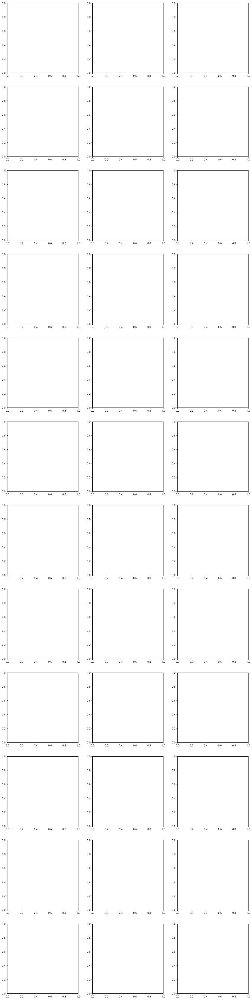

In [ ]:
def save_semantic_heatmap(raw_outputs, pil_image, path):
    """semantic_seg 를 원본 크기로 리사이즈 + 정규화해 grayscale PNG 로 저장.

    (normalized_float_map, (raw_min, raw_max)) 를 반환한다.
    """
    seg = raw_outputs.semantic_seg.float()
    seg = torch.nn.functional.interpolate(
        seg,
        size=(pil_image.height, pil_image.width),
        mode="bilinear",
        align_corners=False,
    )
    seg = seg[0, 0].detach().cpu().numpy()

    lo, hi = float(seg.min()), float(seg.max())
    norm = (seg - lo) / (hi - lo) if hi > lo else np.zeros_like(seg)
    Image.fromarray((norm * 255).astype(np.uint8)).save(path)
    return norm, (lo, hi)


_n_img = len(IMAGE_PATHS)
fig, axes = plt.subplots(_n_img, 3, figsize=(16, 5.5 * _n_img), squeeze=False)

for _row, _path in enumerate(IMAGE_PATHS):
    _img = load_image(_path)
    _, _raw = detect(_img, SINGLE_PROMPT)
    _hp = OUTPUT_DIR / f"{_path.stem}_semantic_seg.png"
    _heat, (_lo, _hi) = save_semantic_heatmap(_raw, _img, _hp)
    print(f"  [{_row}] {_path.name:<44} raw min={_lo:>8.4f}  max={_hi:>8.4f}  -> {_hp.name}")

    axes[_row][0].imshow(_img)
    axes[_row][0].set_title(f"[{_row}] {_path.name}")
    axes[_row][0].axis("off")

    axes[_row][1].imshow(_heat, cmap="gray", vmin=0, vmax=1)
    axes[_row][1].set_title(f'semantic_seg — "{SINGLE_PROMPT}"')
    axes[_row][1].axis("off")

    axes[_row][2].imshow(_img)
    axes[_row][2].imshow(_heat, cmap="jet", alpha=0.5, vmin=0, vmax=1)
    axes[_row][2].set_title("overlay")
    axes[_row][2].axis("off")

plt.tight_layout()
plt.show()

## 8. PCS 마스크 자체 품질 점검 (tracker 임포트 안 함)

> **[전체 이미지]** `IMAGE_PATHS` 에 로드된 이미지를 전부 처리합니다.

**이 섹션의 목적은 "정제(refinement)가 실제로 필요한지"를 결정하기 위한 근거 확보다.**

`Sam3Model`(PCS)이 돌려준 마스크의 **경계 품질**을 육안으로 점검한다.

- 마스크 내부를 채우지 않고 **윤곽선(contour)만 1px 로** 원본 위에 얹는다 — 내부를 칠하면
  경계가 정확한지 안 보인다.
- 하자 부위를 중심으로 **확대(crop)** 한 버전을 나란히 놓아, 경계가 실제 하자 테두리를 얼마나
  타이트하게 따라가는지 판단한다.

판단 기준: 윤곽선이 하자 테두리에서 뭉개지거나 옷 전체로 번지면 -> §9 정제 실험으로,
충분히 타이트하면 -> §9는 실행하지 않아도 된다.

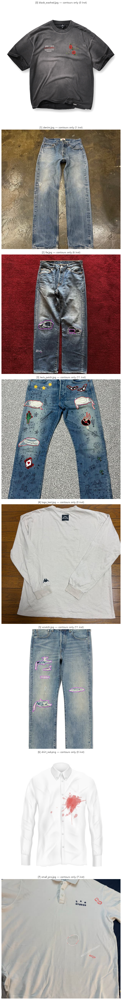

전체 36건 중 confidence 상위 3건을 확대합니다.


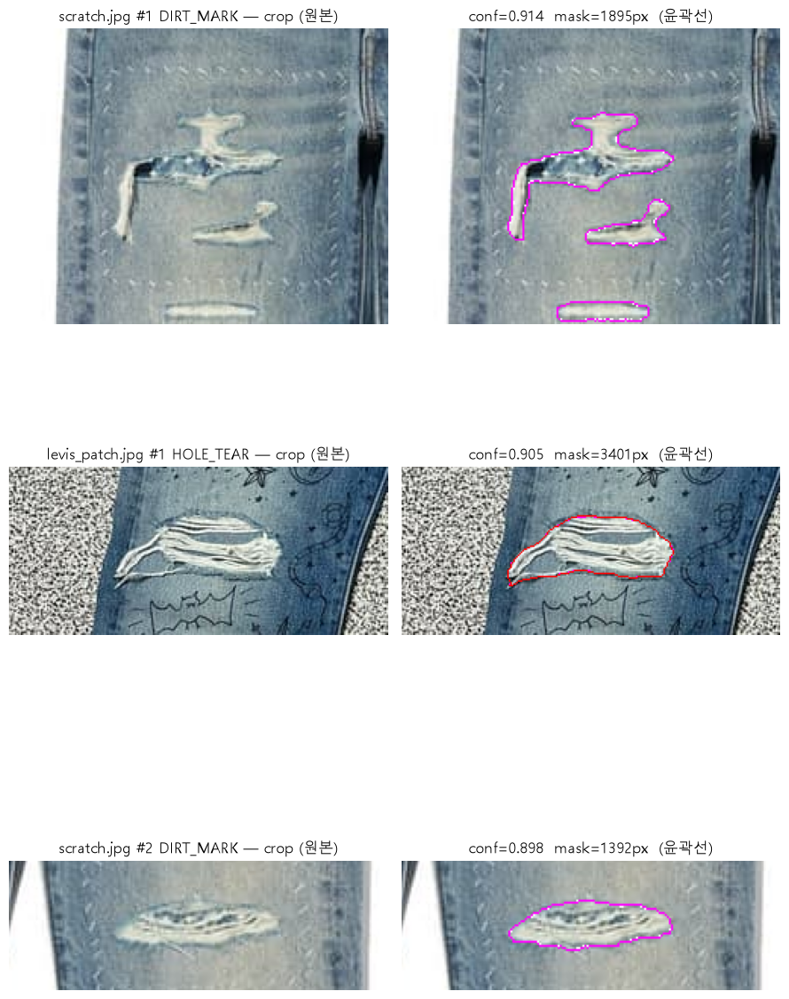

In [14]:
CONTOUR_COLORS = {  # OpenCV BGR
    "STAIN": (0, 0, 255),
    "HOLE_TEAR": (255, 0, 255),
}


def draw_contours(pil_image, insts, thickness=1):
    """마스크 내부를 채우지 않고 윤곽선만 얇게 얹는다. RGB ndarray 반환."""
    canvas = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2BGR)
    for inst in insts:
        contours, _ = cv2.findContours(
            inst["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
        )
        color = CONTOUR_COLORS.get(inst.get("type"), (255, 255, 255))
        cv2.drawContours(canvas, contours, -1, color, thickness)
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def crop_around(img_array, bbox, pad_ratio=CROP_PAD_RATIO):
    """bbox 를 중심으로 pad_ratio 만큼 넓혀 crop 한다."""
    h, w = img_array.shape[:2]
    x1, y1, x2, y2 = bbox
    pad_x = int((x2 - x1) * pad_ratio) + 4
    pad_y = int((y2 - y1) * pad_ratio) + 4
    return img_array[
        max(0, y1 - pad_y) : min(h, y2 + pad_y), max(0, x1 - pad_x) : min(w, x2 + pad_x)
    ]


# 1) 전체 이미지의 윤곽선 오버레이
_n_img = len(results_by_image)
fig, axes = plt.subplots(_n_img, 1, figsize=(10, 8.5 * _n_img), squeeze=False)
_contoured_by_path = {}

for _row, (_path, _insts) in enumerate(results_by_image.items()):
    _view = draw_contours(load_image(_path), _insts)
    _contoured_by_path[_path] = _view
    Image.fromarray(_view).save(OUTPUT_DIR / f"{_path.stem}_contours.png")
    axes[_row][0].imshow(_view)
    axes[_row][0].set_title(f"[{_row}] {_path.name} — contours only ({len(_insts)} inst)")
    axes[_row][0].axis("off")

plt.tight_layout()
plt.show()

# 2) 전체 이미지를 통틀어 confidence 상위 인스턴스만 확대 비교
#    (이미지마다 top-K 를 뽑으면 행이 이미지수 × K 로 불어나 판단이 오히려 어려워진다)
_all = [(path, inst) for path, insts in results_by_image.items() for inst in insts]
_all.sort(key=lambda pair: pair[1]["confidence"], reverse=True)
_topk = _all[:TOPK_CONTOUR_CROPS]

if not _topk:
    print("인스턴스가 없어 확대 비교를 건너뜁니다.")
else:
    print(f"전체 {len(_all)}건 중 confidence 상위 {len(_topk)}건을 확대합니다.")
    fig, axes = plt.subplots(len(_topk), 2, figsize=(9, 4.6 * len(_topk)), squeeze=False)
    for row, (path, inst) in enumerate(_topk):
        axes[row][0].imshow(crop_around(np.array(load_image(path)), inst["bbox"]))
        axes[row][0].set_title(f"{path.name} #{inst['no']} {inst['type']} — crop (원본)")
        axes[row][0].axis("off")

        axes[row][1].imshow(crop_around(_contoured_by_path[path], inst["bbox"]))
        axes[row][1].set_title(
            f"conf={inst['confidence']:.3f}  mask={int(inst['mask'].sum())}px  (윤곽선)"
        )
        axes[row][1].axis("off")
    plt.tight_layout()
    plt.show()

---

# 9. ⚠️ 실험적 섹션 — 8번에서 경계 품질이 부족하다고 판단될 때만 실행

> **[기준 이미지 1장]** `TARGET_INDEX` 이미지의 인스턴스만 정제 대상으로 씁니다.

여기부터는 **앞의 기본 파이프라인(§1~§7)과 분리된 실험**이다. §8의 윤곽선/확대 결과를 보고
"경계가 거칠어서 정제가 필요하다"고 판단했을 때만 실행한다.

### 왜 tracker 를 쓰는가

`Sam3Model`(PCS)의 `forward` 는 `mask_input` / `input_masks` 를 **받지 않는다.**
PCS 시그니처는 `pixel_values / vision_embeds / input_ids / attention_mask / text_embeds /
input_boxes / input_boxes_labels` 가 전부다. 마스크 재입력 방식의 재정제는
`Sam3TrackerModel`(PVS, SAM2 계열 API) 전용 기능이라, 이 실험에서만 tracker 를 새로 임포트한다.

### 확인하려는 것

1. **VRAM** — `Sam3Model` 과 `Sam3TrackerModel` 은 같은 `facebook/sam3` 체크포인트를 쓰는데,
   메모리를 공유하는가? (가설: 서로 다른 `nn.Module` 이라 **공유하지 않는다**. 로드 전후
   `memory_allocated()` 델타로 실측한다.)
2. **경계 개선** — PCS 가 뽑은 각 인스턴스의 box 를 tracker 에 box 프롬프트로 넣어 정제 마스크를
   얻고, 원본 PCS 마스크와 나란히 비교한다.

### ⚠️ 해석 주의

tracker 는 **class-agnostic SAM2 계열 세그멘터**다. box 안의 "물체"를 분할하므로, 하자 box 를
주면 하자가 아니라 **옷 표면 전체**를 잡아 버릴 수 있다. 마스크 픽셀 수가 크게 늘었다면 "정제"가
아니라 "대상이 바뀐" 것일 수 있으니 IoU 와 그림을 같이 보고 판단할 것.

> 임포트 자체는 VRAM 을 쓰지 않는다 — 실제 점유는 `from_pretrained()` 시점에 발생한다.

In [15]:
RUN_TRACKER_REFINE = False  # <- §8에서 경계가 부족하다고 판단되면 True 로 바꾸고 실행

import gc

from transformers import Sam3TrackerModel, Sam3TrackerProcessor


def _vram_report(tag):
    """(allocated_MB, peak_MB) 를 찍고 반환."""
    if DEVICE != "cuda":
        print(f"{tag:<24} (CPU 모드 — VRAM 측정 없음)")
        return (0.0, 0.0)
    alloc = torch.cuda.memory_allocated() / 1024**2
    peak = torch.cuda.max_memory_allocated() / 1024**2
    print(f"{tag:<24} allocated={alloc:9.1f} MB ({alloc / 1024:.2f} GB)   peak={peak:9.1f} MB")
    return (alloc, peak)


def _mask_iou(a, b):
    a_bool, b_bool = a.astype(bool), b.astype(bool)
    union = int(np.logical_or(a_bool, b_bool).sum())
    if union == 0:
        return 0.0
    return float(np.logical_and(a_bool, b_bool).sum() / union)


def load_tracker():
    tracker_processor = Sam3TrackerProcessor.from_pretrained(MODEL_ID)
    tracker_model = Sam3TrackerModel.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE).eval()
    return tracker_model, tracker_processor


def refine_with_tracker(tracker_model, tracker_processor, pil_image, insts):
    """PCS 인스턴스의 bbox 를 box 프롬프트로 넣어 정제 마스크를 얻는다.

    반환: (masks (num_boxes, num_masks, H, W), raw_outputs)
    """
    boxes = [[float(v) for v in inst["bbox"]] for inst in insts]
    inputs = _to_device(
        tracker_processor(images=pil_image, input_boxes=[boxes], return_tensors="pt")
    )
    with torch.no_grad():
        outputs = tracker_model(**inputs, multimask_output=False)
    refined = tracker_processor.post_process_masks(
        outputs.pred_masks.detach().cpu().float(),
        inputs["original_sizes"].cpu(),
    )[0]
    return refined, outputs


if not RUN_TRACKER_REFINE:
    print("RUN_TRACKER_REFINE=False — 실험 섹션을 건너뜁니다.")
    print("§8의 윤곽선/확대 결과에서 경계가 부족하다고 판단되면 True 로 바꾸고 다시 실행하세요.")
elif not instances:
    print("PCS 인스턴스가 0건이라 정제할 대상이 없습니다.")
else:
    targets = instances[:TOPK_CONTOUR_CROPS]
    tracker_model = None
    tracker_processor = None
    pcs_unloaded = False

    before_alloc, _ = _vram_report("tracker 로드 직전")
    try:
        tracker_model, tracker_processor = load_tracker()
    except torch.cuda.OutOfMemoryError as exc:
        print()
        print("[CUDA OOM] PCS 와 Tracker 를 동시에 GPU 에 올리는 건 8GB 에서 버겁습니다.")
        print(f"  원인: {exc}")
        print("  -> PCS 모델을 먼저 내리고 Tracker 단독으로 재시도합니다.")
        del model
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        pcs_unloaded = True
        before_alloc, _ = _vram_report("PCS 해제 후")
        tracker_model, tracker_processor = load_tracker()

    after_alloc, _ = _vram_report("tracker 로드 직후")
    print()
    print(f"tracker 로드로 늘어난 allocated: {after_alloc - before_alloc:+.1f} MB")
    if pcs_unloaded:
        print("  (폴백 경로라 PCS 를 내린 뒤 측정한 값 — '동시 점유 추가분'이 아니다)")
    else:
        print("  같은 facebook/sam3 체크포인트를 쓰지만 Sam3Model 과 Sam3TrackerModel 은 서로 다른")
        print("  nn.Module 이라 가중치 텐서를 공유하지 않는다 — 위 값이 그 실측치다.")

    refined_masks = None
    tracker_out = None
    try:
        refined_masks, tracker_out = refine_with_tracker(
            tracker_model, tracker_processor, image, targets
        )
    except torch.cuda.OutOfMemoryError as exc:
        print()
        print(f"[CUDA OOM] tracker 추론 중 VRAM 부족: {exc}")
        print("  대상 인스턴스 수를 줄이거나(TOPK_CONTOUR_CROPS) 커널을 재시작하세요.")

    if refined_masks is not None:
        iou_scores = tracker_out.iou_scores.detach().float().cpu().numpy().reshape(len(targets), -1)
        fig, axes = plt.subplots(len(targets), 2, figsize=(9, 4.6 * len(targets)), squeeze=False)
        for row, inst in enumerate(targets):
            pcs_mask = inst["mask"]
            ref_mask = refined_masks[row, 0].numpy().astype(np.uint8)
            pcs_view = draw_contours(image, [{"mask": pcs_mask, "type": inst["type"]}])
            ref_view = draw_contours(image, [{"mask": ref_mask, "type": inst["type"]}])

            axes[row][0].imshow(crop_around(pcs_view, inst["bbox"]))
            axes[row][0].set_title(f"#{inst['no']} PCS — {int(pcs_mask.sum())}px")
            axes[row][0].axis("off")

            axes[row][1].imshow(crop_around(ref_view, inst["bbox"]))
            axes[row][1].set_title(
                f"Tracker 정제 — {int(ref_mask.sum())}px\n"
                f"iou_score={iou_scores[row][0]:.3f}   PCS와의 IoU={_mask_iou(pcs_mask, ref_mask):.3f}"
            )
            axes[row][1].axis("off")
        plt.tight_layout()
        plt.show()

        print("해석 주의: tracker 는 class-agnostic 이라 box 안의 '물체'를 분할한다.")
        print("픽셀 수가 크게 늘고 IoU 가 낮으면 '정제'가 아니라 '대상이 바뀐' 것이다.")

    if pcs_unloaded:
        print()
        print("=" * 70)
        print("[중요] 폴백 경로로 PCS 모델(model)을 메모리에서 내렸습니다.")
        print("       §1~§8 이나 아래 run_qc_test() 를 다시 쓰려면 '0-4. 모델 로드' 셀을")
        print("       먼저 다시 실행하세요.")
        print("=" * 70)

RUN_TRACKER_REFINE=False — 실험 섹션을 건너뜁니다.
§8의 윤곽선/확대 결과에서 경계가 부족하다고 판단되면 True 로 바꾸고 다시 실행하세요.


---

## 10. 최종 통합 함수 — `run_qc_test()`

§3(`detect_all`) -> §5(`draw_numbered_boxes`) -> §6(`decide_verdict`) 를 조립만 한다.
로직 중복 없음.

이미지 경로 하나를 넣으면 **(bbox 이미지, instances 리스트, verdict)** 를 한 번에 반환한다.

> §9의 OOM 폴백을 실행했다면 `model` 이 내려가 있으므로, **'0-4. 모델 로드' 셀을 먼저 다시
> 실행**해야 이 함수가 동작한다.

In [15]:
import json


def run_qc_test(image_path, prompts=DEFECT_PROMPTS, verdict_thresholds=VERDICT_THRESHOLDS):
    """이미지 1장을 QC 파이프라인에 통과시킨다.

    Args:
        image_path: 검사할 이미지 경로
        prompts: {하자유형: 영어 명사구} — 기본값 DEFECT_PROMPTS
        verdict_thresholds: (review_at, fail_at) — 기본값 VERDICT_THRESHOLDS

    Returns:
        annotated (np.ndarray): 번호 + 한글 태그 + 빨간 bbox 가 그려진 RGB 이미지
        instances (list[dict]): [{"no","type","label","bbox","confidence"}, ...] — JSON 직렬화 가능
        verdict (str): "PASS" | "REVIEW" | "FAIL"
    """
    pil_image = Image.open(image_path).convert("RGB")
    # inspect_image = 의류 크롭 -> 크롭 안에서 탐지 -> 의류 실루엣 재확인 -> 주름·그림자 억제 (§3)
    detected, _trace = inspect_image(pil_image)
    annotated = draw_numbered_boxes(pil_image, detected)
    decided, _peak = decide_verdict(detected, verdict_thresholds)
    # mask(ndarray)는 JSON 직렬화가 안 되므로 to_serializable 이 걸러 준다.
    return annotated, to_serializable(detected), decided

### 실행 예시 — 로드한 이미지 전체 배치 실행

`run_qc_test()` 는 이미지 1장을 받으므로, 전체에 돌리려면 그냥 루프를 감으면 된다.
결과는 `outputs/<파일명>_qc.json` 과 `outputs/qc_summary.json` 으로 저장한다.

  [0] black_washed.jpg                             PASS      0건
  [1] denim.jpg                                    REVIEW    1건
  [2] fix.jpg                                      FAIL      6건
  [3] levis_patch.jpg                              FAIL     11건
  [4] logo_test.jpg                                PASS      0건
  [5] scratch.jpg                                  FAIL     11건
  [6] shirt_red.png                                PASS      0건
  [7] small_pro.jpg                                REVIEW    7건

저장 완료 -> outputs\masking

--- 기준 이미지 상세 (JSON 직렬화 확인) ---
[
  {
    "no": 1,
    "type": "STAIN",
    "prompt": "a stain on fabric",
    "bbox": [
      339,
      288,
      403,
      346
    ],
    "confidence": 0.7344,
    "garment_overlap": 1.0,
    "label": "오염"
  },
  {
    "no": 2,
    "type": "STAIN",
    "prompt": "a stain on fabric",
    "bbox": [
      457,
      393,
      490,
      410
    ],
    "confidence": 0.4192,
    "garment_overlap": 1.0,
    "label": "오염"
  },

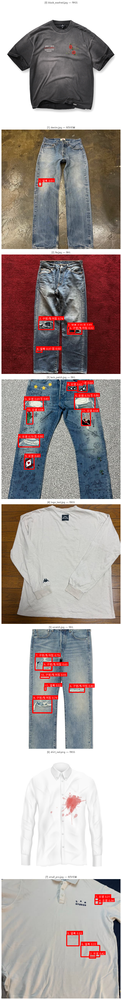

In [17]:
qc_results = {}

for _i, _path in enumerate(IMAGE_PATHS):
    _img, _insts, _v = run_qc_test(_path)
    qc_results[_path] = {"annotated": _img, "instances": _insts, "verdict": _v}
    _payload = {"image": _path.name, "verdict": _v, "instances": _insts}
    (OUTPUT_DIR / f"{_path.stem}_qc.json").write_text(
        json.dumps(_payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"  [{_i}] {_path.name:<44} {_v:<7} {len(_insts):>3}건")

_summary = [
    {"image": p.name, "verdict": r["verdict"], "instances": len(r["instances"])}
    for p, r in qc_results.items()
]
(OUTPUT_DIR / "qc_summary.json").write_text(
    json.dumps(_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

print()
print(f"저장 완료 -> {OUTPUT_DIR}")
print()
print("--- 기준 이미지 상세 (JSON 직렬화 확인) ---")
print(json.dumps(qc_results[IMAGE_PATH]["instances"], ensure_ascii=False, indent=2))

_n_img = len(qc_results)
fig, axes = plt.subplots(_n_img, 1, figsize=(10, 8.5 * _n_img), squeeze=False)
for _row, (_path, _r) in enumerate(qc_results.items()):
    axes[_row][0].imshow(_r["annotated"])
    axes[_row][0].set_title(f"[{_row}] {_path.name} — {_r['verdict']}")
    axes[_row][0].axis("off")
plt.tight_layout()
plt.show()

---

## 결론 (실행 후 채울 것)

SAM3 를 QC 백엔드 후보로 채택할지 판단하는 항목이다. 위 셀들을 돌린 뒤 실측값으로 채운다.

| # | 확인 항목 | 근거 셀 | 결과 |
| --- | --- | --- | --- |
| 1 | 하자 인스턴스가 **개별로** 분리되는가 (CLIPSeg 는 히트맵 1장 -> 직접 blob 추출) | §1, §3 | |
| 2 | **찢어짐/구멍**(`a tear`, `a hole`)이 CLIPSeg 보다 나은가 — LAB-12 가 지목한 약점 | §3 | |
| 3 | 한국어 프롬프트가 쓸 만한가 | §2 | |
| 4 | 8GB VRAM 에 상시 올려둘 만한가 / 반복 호출 시 누수는 없는가 | §4 | |
| 5 | 마스크 경계가 정제 없이 쓸 만한가 | §8 | |
| 6 | (5가 아니라면) tracker 정제가 실제로 개선을 주는가 / VRAM 추가분이 감당되는가 | §9 | |
| 7 | 판정 임계치 0.4 / 0.7 이 이 모델의 score 스케일에 맞는가 | §6 | |

### 후속 작업

채택 시 `.claude/plans/ai/005-quality-inspection-prototype.md` §고도화 경로 **항목 5
(찢어짐 보완 모델 병행 — `DefectSegmenter` 구현체 추가)** 로 이어진다. 그때 주의할 것:

- **임계치는 백엔드별로 다시 스윕해야 한다.** CLIPSeg 의 sigmoid 확률 스케일과 SAM3 의
  `pred_logits.sigmoid() * presence_logits.sigmoid()` 스케일은 서로 비교할 수 없다.
- 이 노트북의 `PASS/REVIEW/FAIL` 3단계는 프로덕션 스키마
  (`DETECTED`/`SUSPECTED` + `condition_score`/`condition_grade`)와 **다르다.** 프로토타입
  단순화이지 계약 변경 제안이 아니다.
- 추론 코드는 `AI/app/` 이 아니라 리포 루트 `worker/` 에 둔다 (`AI/docs/infra-architecture.md` §3.2).
  배포 이미지에는 torch 가 없다.

---

# +@. 발표 자료용 — 지정 이미지 원본 / 오버레이 / bbox(instance)

위 §5·§7·§8 은 `IMAGE_PATHS` 전체를 한 Figure 에 몰아서 보여준다. 발표 자료에는
일부 이미지만, 그것도 이미지별로 별도 Figure 로 필요해서 이 섹션을 따로 둔다.

- `PRESENTATION_FILES` 에 **파일명**만 적으면 된다(§0-5 출력에 찍힌 이름 그대로). 인덱스가
  아니라 파일명 기준이라 `IMAGE_PATHS` 순서가 바뀌어도 안전하다.
- 이미지 1장당 별도 Figure 1개, 원본 / 오버레이(`semantic_seg` 히트맵, §7과 동일 방식) /
  bbox(instance, `run_qc_test()` 결과 그대로 — 실제 판정에 쓰인 인스턴스) 3칸 구성.
- PNG 는 `outputs/<파일명>_presentation_{original,overlay,bbox}.png` 로 각각 저장한다.

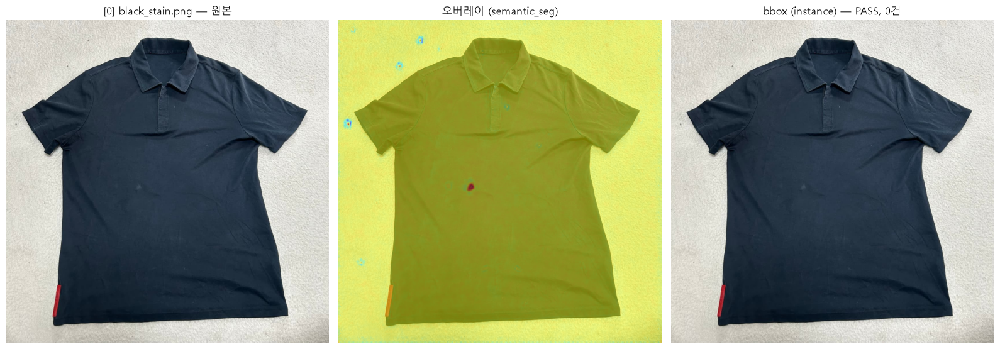

[0] black_stain.png 저장 완료 -> black_stain_presentation_original.png / black_stain_presentation_overlay.png / black_stain_presentation_bbox.png


In [25]:
# ── 발표용 이미지만 골라서 원본/오버레이/bbox 를 따로따로 보여준다 ──────────
# 여기에 파일명만 적으면 된다(§0-5 출력에 찍힌 이름 그대로, 확장자 포함).
# 예: PRESENTATION_FILES = ["stain_01.jpg", "hole_03.png"]
PRESENTATION_FILES = ["black_stain.png"]


def _resolve_presentation_path(name):
    matches = [p for p in IMAGE_PATHS if p.name == name]
    if not matches:
        raise FileNotFoundError(
            f"'{name}' 을(를) IMAGE_PATHS 에서 찾을 수 없습니다. §0-5 출력의 파일명을 확인하세요."
        )
    return matches[0]


for _name in PRESENTATION_FILES:
    _path = _resolve_presentation_path(_name)
    _idx = IMAGE_PATHS.index(_path)
    _img = load_image(_path)

    # bbox(instance) — run_qc_test() 그대로(실제 판정에 쓰인 인스턴스와 동일)
    _annotated, _insts, _verdict = run_qc_test(_path)

    # 오버레이 — semantic_seg 히트맵(§7과 동일 방식)
    _, _raw = detect(_img, SINGLE_PROMPT)
    _overlay_path = OUTPUT_DIR / f"{_path.stem}_presentation_overlay.png"
    _heat, (_lo, _hi) = save_semantic_heatmap(_raw, _img, _overlay_path)

    _orig_path = OUTPUT_DIR / f"{_path.stem}_presentation_original.png"
    _img.save(_orig_path)
    _bbox_path = OUTPUT_DIR / f"{_path.stem}_presentation_bbox.png"
    Image.fromarray(_annotated).save(_bbox_path)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

    axes[0].imshow(_img)
    axes[0].set_title(f"[{_idx}] {_path.name} — 원본")
    axes[0].axis("off")

    axes[1].imshow(_img)
    axes[1].imshow(_heat, cmap="jet", alpha=0.5, vmin=0, vmax=1)
    axes[1].set_title("오버레이 (semantic_seg)")
    axes[1].axis("off")

    axes[2].imshow(_annotated)
    axes[2].set_title(f"bbox (instance) — {_verdict}, {len(_insts)}건")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()
    print(f"[{_idx}] {_path.name} 저장 완료 -> {_orig_path.name} / {_overlay_path.name} / {_bbox_path.name}")